# Tutorial answers, Q2: supermarket checkout (M/M/c)

48 customers per hour, 4-minute mean checkout, £12 per lane per hour and £0.20 per minute of waiting, over 4 hours with 2–6 lanes.

*Original script: `5 Source Files/Python/Q2_Supermarket_Checkout.py` (kept unchanged). Same code, split into steps; the charts are drawn in one cell, and a replication check is added at the end (erratum C5). Run the cells in order; the first cell installs SimPy. Runs in the browser and in Jupyter on your own computer.*

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install simpy

In [2]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

**Global data collection.**

In [3]:
# Global data collection
wait_times = []
system_times = []
queue_lengths = []

**`customer`** (function): Customer arrives, waits for checkout, gets served, and leaves.

In [4]:
def customer(env, name, checkouts, service_rate):
    """Customer arrives, waits for checkout, gets served, and leaves."""
    arrival_time = env.now
    
    # Record queue length at arrival
    queue_lengths.append(len(checkouts.queue))
    
    with checkouts.request() as request:
        yield request
        
        # Record wait time
        wait_time = env.now - arrival_time
        wait_times.append(wait_time)
        
        # Service time (exponential)
        service_time = random.expovariate(service_rate)
        yield env.timeout(service_time)
        
        # Record total system time
        system_time = env.now - arrival_time
        system_times.append(system_time)

**`customer_generator`** (function): Generate customers arriving at the supermarket.

In [5]:
def customer_generator(env, checkouts, arrival_rate, service_rate):
    """Generate customers arriving at the supermarket."""
    customer_number = 0
    while True:
        # Wait for next customer
        yield env.timeout(random.expovariate(arrival_rate))
        
        customer_number += 1
        env.process(customer(env, f"Customer {customer_number}", checkouts, service_rate))

**`run_simulation`** (function): Run a single simulation and return statistics.

In [6]:
def run_simulation(num_checkouts, arrival_rate, service_rate, sim_time, random_seed=42):
    """Run a single simulation and return statistics."""
    
    # Reset global data
    global wait_times, system_times, queue_lengths
    wait_times = []
    system_times = []
    queue_lengths = []
    
    # Setup
    random.seed(random_seed)
    env = simpy.Environment()
    checkouts = simpy.Resource(env, capacity=num_checkouts)
    
    # Start generator
    env.process(customer_generator(env, checkouts, arrival_rate, service_rate))
    
    # Run simulation
    env.run(until=sim_time)
    
    # Calculate statistics
    total_customers = len(wait_times)
    avg_wait = np.mean(wait_times) if wait_times else 0
    avg_system_time = np.mean(system_times) if system_times else 0
    avg_queue_length = np.mean(queue_lengths) if queue_lengths else 0
    max_queue_length = max(queue_lengths) if queue_lengths else 0
    pct_waited = 100 * sum(1 for w in wait_times if w > 0) / total_customers if total_customers > 0 else 0
    
    # Calculate utilization
    utilization = arrival_rate / (num_checkouts * service_rate)
    
    return {
        'num_checkouts': num_checkouts,
        'utilization': utilization,
        'total_customers': total_customers,
        'avg_wait': avg_wait,
        'avg_system_time': avg_system_time,
        'avg_queue_length': avg_queue_length,
        'max_queue_length': max_queue_length,
        'pct_waited': pct_waited
    }

**`calculate_cost`** (function): Calculate total cost for the simulation period.

In [7]:
def calculate_cost(stats, staff_cost_per_hour, wait_cost_per_minute, sim_hours):
    """Calculate total cost for the simulation period."""
    
    # Staff cost
    staff_cost = stats['num_checkouts'] * staff_cost_per_hour * sim_hours
    
    # Wait cost (total wait time across all customers)
    total_wait_time = stats['total_customers'] * stats['avg_wait']
    wait_cost = total_wait_time * wait_cost_per_minute
    
    # Total cost
    total_cost = staff_cost + wait_cost
    
    return {
        'staff_cost': staff_cost,
        'wait_cost': wait_cost,
        'total_cost': total_cost
    }

**Simulation parameters.**

In [8]:
# Simulation parameters
SIM_TIME = 240  # 4 hours in minutes
ARRIVAL_RATE = 48 / 60  # 48 customers/hour = 0.8 customers/minute
SERVICE_TIME_MEAN = 4  # minutes
SERVICE_RATE = 1 / SERVICE_TIME_MEAN  # customers per minute per checkout

**Cost parameters.**

In [9]:
# Cost parameters
STAFF_COST_PER_HOUR = 12  # £12 per hour per checkout
WAIT_COST_PER_MINUTE = 0.20  # £0.20 per minute of wait
SIM_HOURS = SIM_TIME / 60  # 4 hours

print("="*80)
print("SUPERMARKET CHECKOUT OPTIMIZATION (M/M/c QUEUE)")
print("="*80)
print(f"Arrival rate: {ARRIVAL_RATE*60:.1f} customers/hour")
print(f"Service time: {SERVICE_TIME_MEAN} minutes average per customer")
print(f"Simulation time: {SIM_TIME} minutes ({SIM_HOURS} hours)")
print(f"Staff cost: £{STAFF_COST_PER_HOUR}/hour per checkout")
print(f"Wait cost: £{WAIT_COST_PER_MINUTE}/minute per customer")
print()

results = []
checkout_configs = [2, 3, 4, 5, 6]

for num_checkouts in checkout_configs:
    print(f"\n{'='*80}")
    print(f"Configuration: {num_checkouts} Checkout Lanes")
    print(f"{'='*80}")
    
    stats = run_simulation(num_checkouts, ARRIVAL_RATE, SERVICE_RATE, SIM_TIME)
    costs = calculate_cost(stats, STAFF_COST_PER_HOUR, WAIT_COST_PER_MINUTE, SIM_HOURS)
    
    # Combine statistics and costs
    stats.update(costs)
    results.append(stats)
    
    print(f"\nPerformance Metrics:")
    print(f"  System utilization (ρ): {stats['utilization']:.3f}")
    print(f"  Total customers served: {stats['total_customers']}")
    print(f"  Average wait time: {stats['avg_wait']:.2f} minutes")
    print(f"  Average queue length: {stats['avg_queue_length']:.2f} customers")
    print(f"  Maximum queue length: {stats['max_queue_length']} customers")
    print(f"  Customers who waited: {stats['pct_waited']:.1f}%")
    
    print(f"\nCost Analysis:")
    print(f"  Staff cost: £{stats['staff_cost']:.2f}")
    print(f"  Wait cost: £{stats['wait_cost']:.2f}")
    print(f"  TOTAL COST: £{stats['total_cost']:.2f}")

SUPERMARKET CHECKOUT OPTIMIZATION (M/M/c QUEUE)
Arrival rate: 48.0 customers/hour
Service time: 4 minutes average per customer
Simulation time: 240 minutes (4.0 hours)
Staff cost: £12/hour per checkout
Wait cost: £0.2/minute per customer


Configuration: 2 Checkout Lanes

Performance Metrics:
  System utilization (ρ): 1.600
  Total customers served: 120
  Average wait time: 41.27 minutes
  Average queue length: 27.33 customers
  Maximum queue length: 54 customers
  Customers who waited: 98.3%

Cost Analysis:
  Staff cost: £96.00
  Wait cost: £990.39
  TOTAL COST: £1086.39

Configuration: 3 Checkout Lanes

Performance Metrics:
  System utilization (ρ): 1.067
  Total customers served: 158
  Average wait time: 11.76 minutes
  Average queue length: 9.05 customers
  Maximum queue length: 25 customers
  Customers who waited: 88.0%

Cost Analysis:
  Staff cost: £144.00
  Wait cost: £371.56
  TOTAL COST: £515.56

Configuration: 4 Checkout Lanes

Performance Metrics:
  System utilization (ρ): 0

**Find optimal configuration.**

In [10]:
# Find optimal configuration
optimal = min(results, key=lambda x: x['total_cost'])

print("\n" + "="*80)
print("SUMMARY COMPARISON")
print("="*80)
print(f"{'Lanes':<8} {'ρ':<8} {'Avg Wait':<12} {'Queue Len':<12} {'Staff £':<12} {'Wait £':<12} {'Total £':<12}")
print("-"*80)
for stats in results:
    print(f"{stats['num_checkouts']:<8} {stats['utilization']:<8.3f} {stats['avg_wait']:<12.2f} "
          f"{stats['avg_queue_length']:<12.2f} {stats['staff_cost']:<12.2f} "
          f"{stats['wait_cost']:<12.2f} {stats['total_cost']:<12.2f}")

print("\n" + "="*80)
print("RECOMMENDATION")
print("="*80)
print(f"\nOptimal number of checkout lanes: {optimal['num_checkouts']}")
print(f"Minimum total cost: £{optimal['total_cost']:.2f}")
print(f"\nAt this configuration:")
print(f"  - Utilization: {optimal['utilization']:.1%} (system is {'stable' if optimal['utilization'] < 1 else 'UNSTABLE'})")
print(f"  - Average wait time: {optimal['avg_wait']:.2f} minutes")
print(f"  - {optimal['pct_waited']:.1f}% of customers experience a wait")
print(f"\nRationale:")
if optimal['num_checkouts'] == min(checkout_configs):
    print("  Minimum configuration tested - consider reducing further")
elif optimal['num_checkouts'] == max(checkout_configs):
    print("  Maximum configuration tested - may need more lanes")
else:
    print(f"  Adding another lane would increase staff costs by £{STAFF_COST_PER_HOUR * SIM_HOURS:.2f}")
    print(f"  but only reduce wait costs marginally (diminishing returns)")


SUMMARY COMPARISON
Lanes    ρ        Avg Wait     Queue Len    Staff £      Wait £       Total £     
--------------------------------------------------------------------------------
2        1.600    41.27        27.33        96.00        990.39       1086.39     
3        1.067    11.76        9.05         144.00       371.56       515.56      
4        0.800    0.85         0.55         192.00       29.64        221.64      
5        0.640    0.28         0.19         240.00       9.82         249.82      
6        0.533    0.15         0.09         288.00       5.59         293.59      

RECOMMENDATION

Optimal number of checkout lanes: 4
Minimum total cost: £221.64

At this configuration:
  - Utilization: 80.0% (system is stable)
  - Average wait time: 0.85 minutes
  - 41.7% of customers experience a wait

Rationale:
  Adding another lane would increase staff costs by £48.00
  but only reduce wait costs marginally (diminishing returns)


**Charts.** All four panels are drawn in this one cell, so they show in the browser too (the original script draws them over several steps). The picture is also saved as a PNG next to the notebook.


Visualization saved as 'Q2_Supermarket_Checkout_Results.png'


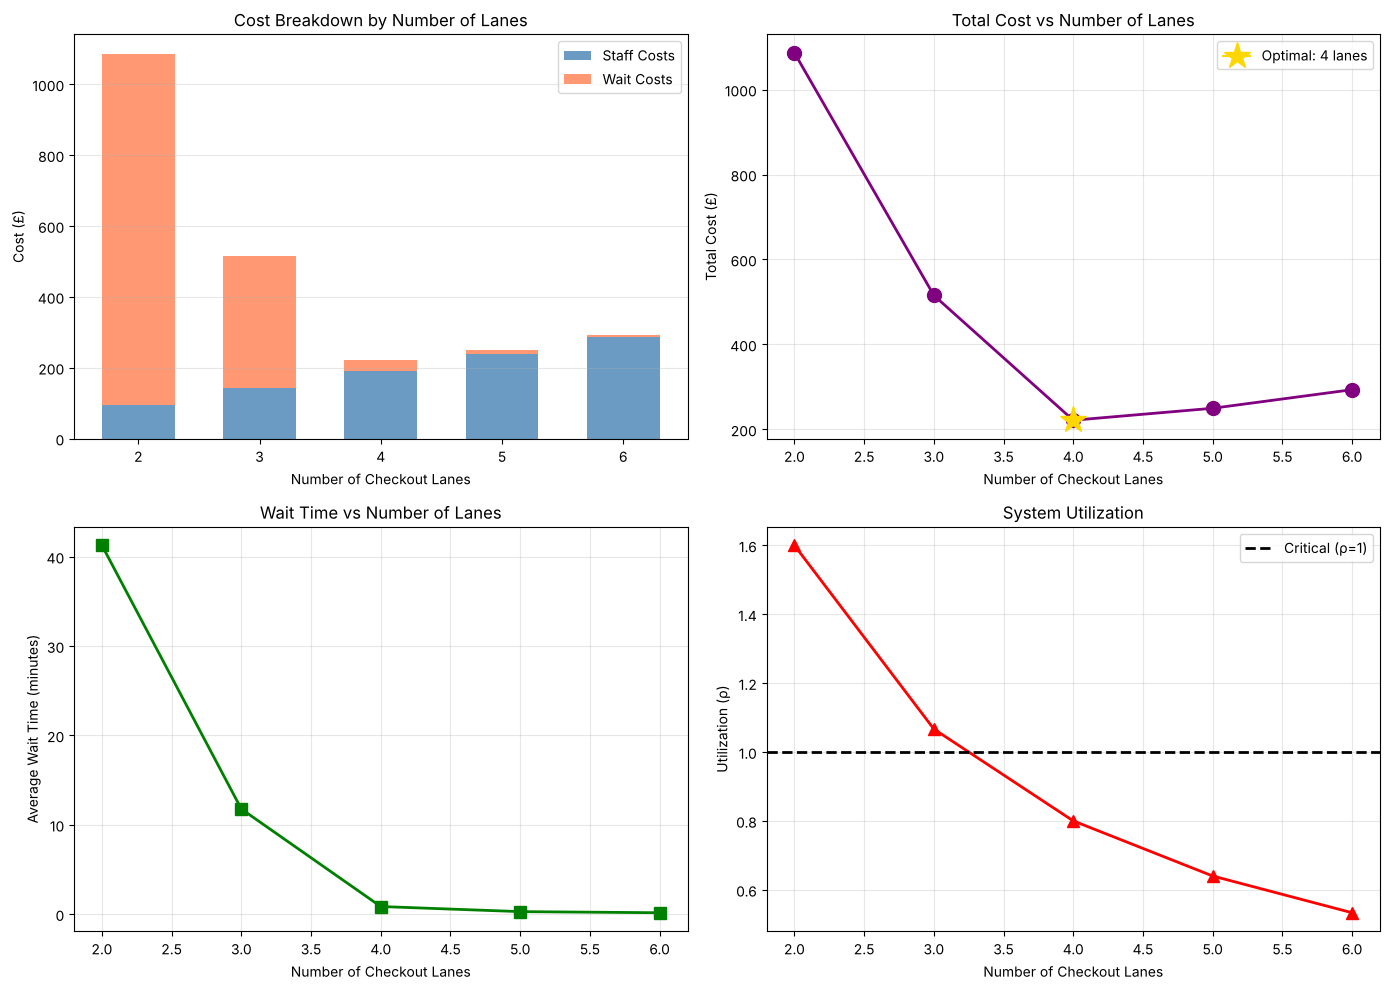

In [11]:
# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Extract data for plotting
lanes = [r['num_checkouts'] for r in results]
avg_waits = [r['avg_wait'] for r in results]
staff_costs = [r['staff_cost'] for r in results]
wait_costs = [r['wait_cost'] for r in results]
total_costs = [r['total_cost'] for r in results]
utilizations = [r['utilization'] for r in results]

# Plot 1: Cost breakdown (stacked bar)
width = 0.6
axes[0, 0].bar(lanes, staff_costs, width, label='Staff Costs', color='steelblue', alpha=0.8)
axes[0, 0].bar(lanes, wait_costs, width, bottom=staff_costs, label='Wait Costs', color='coral', alpha=0.8)
axes[0, 0].set_xlabel('Number of Checkout Lanes')
axes[0, 0].set_ylabel('Cost (£)')
axes[0, 0].set_title('Cost Breakdown by Number of Lanes')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Plot 2: Total cost curve
axes[0, 1].plot(lanes, total_costs, marker='o', linewidth=2, markersize=10, color='purple')
optimal_idx = total_costs.index(min(total_costs))
axes[0, 1].plot(lanes[optimal_idx], total_costs[optimal_idx], 
                marker='*', markersize=20, color='gold', 
                label=f'Optimal: {lanes[optimal_idx]} lanes')
axes[0, 1].set_xlabel('Number of Checkout Lanes')
axes[0, 1].set_ylabel('Total Cost (£)')
axes[0, 1].set_title('Total Cost vs Number of Lanes')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Average wait time
axes[1, 0].plot(lanes, avg_waits, marker='s', linewidth=2, markersize=8, color='green')
axes[1, 0].set_xlabel('Number of Checkout Lanes')
axes[1, 0].set_ylabel('Average Wait Time (minutes)')
axes[1, 0].set_title('Wait Time vs Number of Lanes')
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Utilization
axes[1, 1].plot(lanes, utilizations, marker='^', linewidth=2, markersize=8, color='red')
axes[1, 1].axhline(y=1.0, color='black', linestyle='--', linewidth=2, label='Critical (ρ=1)')
axes[1, 1].set_xlabel('Number of Checkout Lanes')
axes[1, 1].set_ylabel('Utilization (ρ)')
axes[1, 1].set_title('System Utilization')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Q2_Supermarket_Checkout_Results.png', dpi=300, bbox_inches='tight')
print("\nVisualization saved as 'Q2_Supermarket_Checkout_Results.png'")
plt.show()

## Check: one run is not enough (added)

The table above comes from **one** 4-hour run with seed 42, and in that run 4 lanes looks cheapest. Repeating the
experiment with 200 different seeds and averaging gives a fairer comparison. The 95% confidence interval is
mean ± 1.96 × standard deviation / √200.

In [12]:
reps = 200
print(f"{'Lanes':<7}{'Mean total cost (£)':>21}{'95% CI (±)':>13}")
rep_cost = {}
for num_checkouts in checkout_configs:
    costs = []
    for seed in range(reps):
        s = run_simulation(num_checkouts, ARRIVAL_RATE, SERVICE_RATE, SIM_TIME, random_seed=seed)
        costs.append(calculate_cost(s, STAFF_COST_PER_HOUR, WAIT_COST_PER_MINUTE, SIM_HOURS)['total_cost'])
    half = 1.96 * np.std(costs, ddof=1) / np.sqrt(reps)
    rep_cost[num_checkouts] = np.mean(costs)
    print(f"{num_checkouts:<7}{np.mean(costs):>21.2f}{half:>13.2f}")

best = min(rep_cost, key=rep_cost.get)
print(f"\nAveraged over {reps} runs, the cheapest option is {best} lanes.")

Lanes    Mean total cost (£)   95% CI (±)


2                    1162.46        32.06


3                     612.96        38.64


4                     285.58        11.39


5                     262.92         2.65


6                     294.46         0.93

Averaged over 200 runs, the cheapest option is 5 lanes.


**Answer.** On average 5 lanes is cheapest. The single run above favoured 4 lanes only because it was a lucky run with short waits. With 4 lanes the system is 80% busy, and its cost varies a lot from run to run.